### Import and helper

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os, glob
from scipy.stats import pearsonr

try:
    import utils.process_analysis
except ImportError as e:
    print(f"\nSTILL FAILING: {e}")

sns.set_theme(font='Arial')
sns.set(style="ticks", context="paper")

#### Directories

In [2]:
DATA_DIR        = "../data/02_processed_combined_data"
OUTPUT_DIR      = "../data/04_analysis/channel_relationships/"
current_dir     = os.getcwd()
CONDITIONS_FILE = os.path.abspath(os.path.join(current_dir, "../data/sub_conditions.csv"))
if not os.path.exists(OUTPUT_DIR): 
    os.makedirs(OUTPUT_DIR, exist_ok=True)

In [3]:
#### 1 LOAD DATA 

In [4]:
# A. Get Subject List
if os.path.exists(CONDITIONS_FILE):
    pc_subjs = utils.process_analysis.get_subjects_by_condition(CONDITIONS_FILE, target_condition='PC')
    print(f"Targeting {len(pc_subjs)} subjects from condition 'PC'.")
else:
    print("Warning: Conditions file not found. Ensure 'pc_subjs' is defined.")

# B. Load the Dictionary of DataFrames
results = utils.process_analysis.load_filtered_physiological_data(DATA_DIR, pc_subjs)

# C. Sanity Check
if 'Gaze_X' not in results or results['Gaze_X'].empty:
    raise ValueError("Error: 'results' dictionary is empty or missing Gaze data. Check data loading.")
else:
    print(f"Data Loaded Successfully. Signals: {list(results.keys())}")

Targeting 99 subjects from condition 'PC'.
Scanning 193 files against 99 subject IDs...
Successfully loaded 96 valid subjects.
Data Loaded Successfully. Signals: ['GSR', 'Heart_Rate', 'Pupil_Mean', 'Gaze_X', 'Gaze_Y']


### Run HIERARCHY ANALYSIS: SORTED MATRICES


--- Running Matrix Reordering Analysis ---
Computing Gaze Consistency...
Processing Pupil_Mean...
Processing Heart_Rate...
Processing GSR...


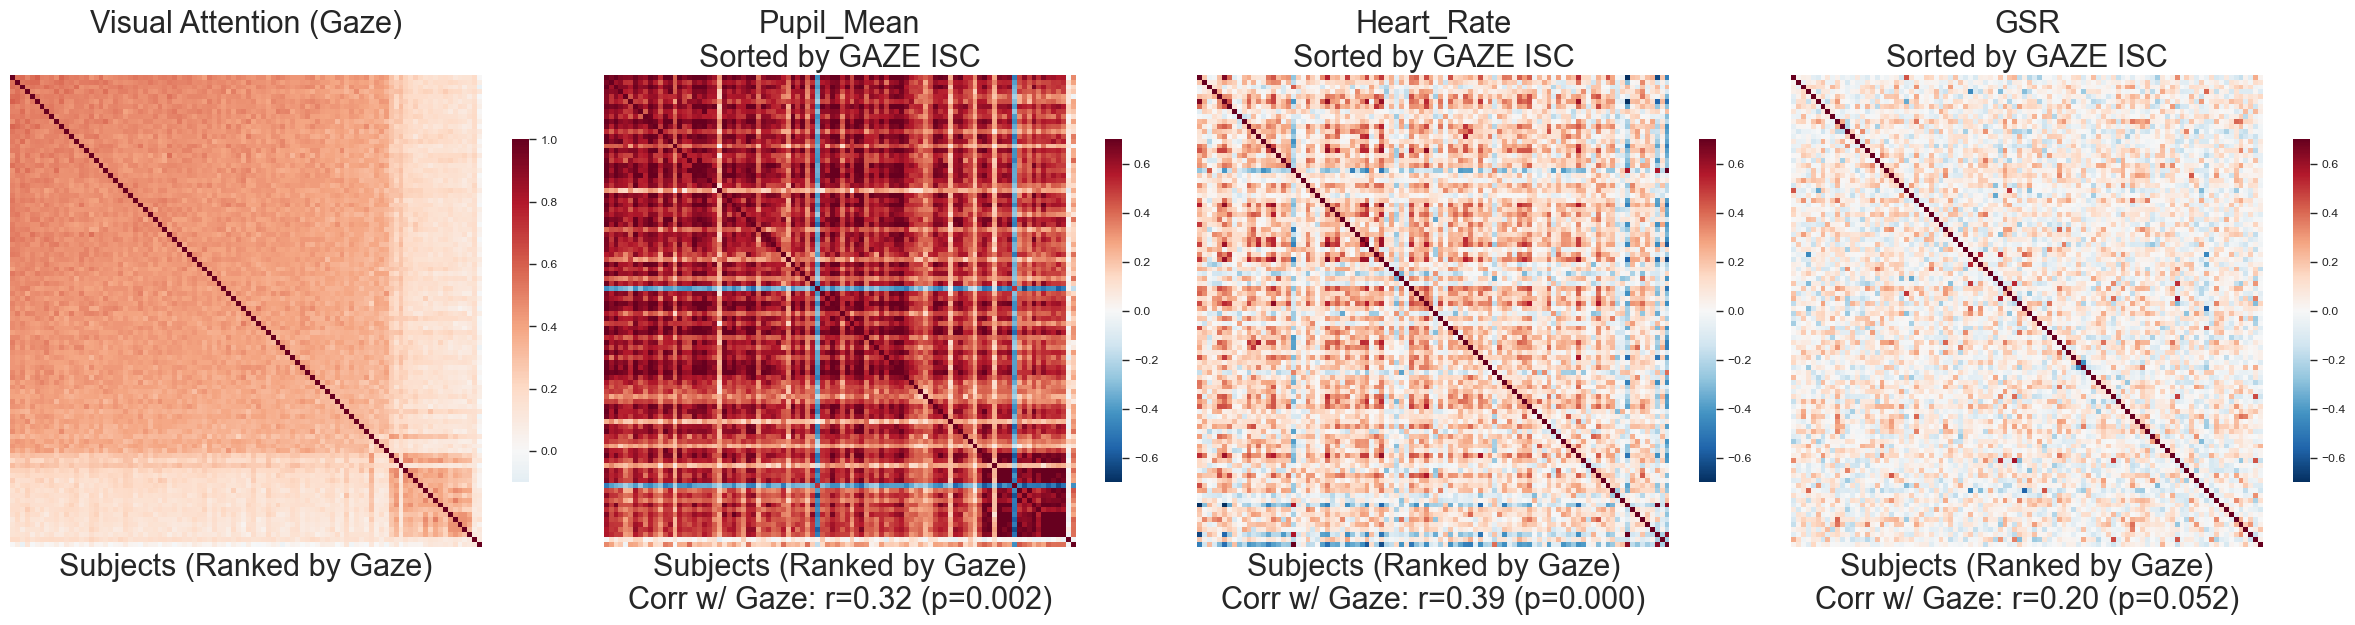

Analysis Complete.


In [5]:
#plt.rc('font', size=12) 

print("\n--- Running Matrix Reordering Analysis ---")

# A. DEFINE THE "DRIVER" (Visual Attention)
# We use the average of Gaze X and Y LOO scores as the "Attention Quality" index
print("Computing Gaze Consistency...")
loo_gaze_x = utils.process_analysis.compute_loo_score(results['Gaze_X'])
loo_gaze_y = utils.process_analysis.compute_loo_score(results['Gaze_Y'])
gaze_sync_scores = (loo_gaze_x + loo_gaze_y) / 2

# Calculate the Driver Matrix (Average of X and Y pairwise matrices)
mat_gaze_x = utils.process_analysis.compute_pairwise_matrix(results['Gaze_X'])
mat_gaze_y = utils.process_analysis.compute_pairwise_matrix(results['Gaze_Y'])
mat_gaze_combined = (mat_gaze_x + mat_gaze_y) / 2

# B. DETERMINE SORTING ORDER
# Sort from Highest Gaze Sync -> Lowest Gaze Sync
sort_indices = np.argsort(gaze_sync_scores)[::-1]

# Apply sorting to the Driver Matrix
sorted_gaze_mat = mat_gaze_combined[sort_indices][:, sort_indices]

# C. ANALYZE & PLOT "PASSENGER" SIGNALS
passenger_signals = ['Pupil_Mean', 'Heart_Rate', 'GSR'] 
# Note: Check if they exist in your 'results'
passenger_signals = [s for s in passenger_signals if s in results]

# Create Figure
fig, axes = plt.subplots(1, 1 + len(passenger_signals), figsize=(6 * (1+len(passenger_signals)), 6))
# If only one passenger, ensure axes is iterable
if len(passenger_signals) == 0: axes = [axes]
elif not isinstance(axes, np.ndarray): axes = [axes]

# --- Plot 1: GAZE (Reference) ---
sns.heatmap(sorted_gaze_mat, ax=axes[0], cmap='RdBu_r', center=0, vmin=-0.1, vmax=1.0, 
            square=True, cbar_kws={'shrink': 0.6})
axes[0].set_title("Visual Attention (Gaze)\n ", fontsize = 22)
axes[0].set_xlabel("Subjects (Ranked by Gaze)", fontsize = 22)
axes[0].set_yticks([])
axes[0].set_xticks([])

# --- Loop for Passengers ---
for i, signal in enumerate(passenger_signals):
    ax_idx = i + 1
    
    print(f"Processing {signal}...")
    
    # 1. Compute Scores & Matrix
    mat_physio = utils.process_analysis.compute_pairwise_matrix(results[signal])
    loo_physio = utils.process_analysis.compute_loo_score(results[signal])
    
    # 2. Sort Matrix using GAZE indices (Crucial Step!)
    sorted_physio_mat = mat_physio[sort_indices][:, sort_indices]
    
    # 3. Stats: Does Gaze predict this signal?
    r_val, p_val = pearsonr(gaze_sync_scores, loo_physio)
    
    # 4. Plot
    # Adjust vmax lower for physiology (usually 0.3-0.6)
    vmax_val = 0.7 #if signal == 'GSR' else 0.7 
    
    sns.heatmap(sorted_physio_mat, ax=axes[ax_idx], cmap='RdBu_r', center=0, vmin=-vmax_val, vmax=vmax_val, 
                square=True, cbar_kws={'shrink': 0.6})
    
    axes[ax_idx].set_title(f"{signal}\nSorted by GAZE ISC", fontsize = 22)
    axes[ax_idx].set_xlabel(f"Subjects (Ranked by Gaze)\nCorr w/ Gaze: r={r_val:.2f} (p={p_val:.3f})", fontsize = 22)
    axes[ax_idx].set_yticks([])
    axes[ax_idx].set_xticks([])

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Figure_Hierarchy_SortedMatrices.png"), dpi=300)
plt.show()

print("Analysis Complete.")

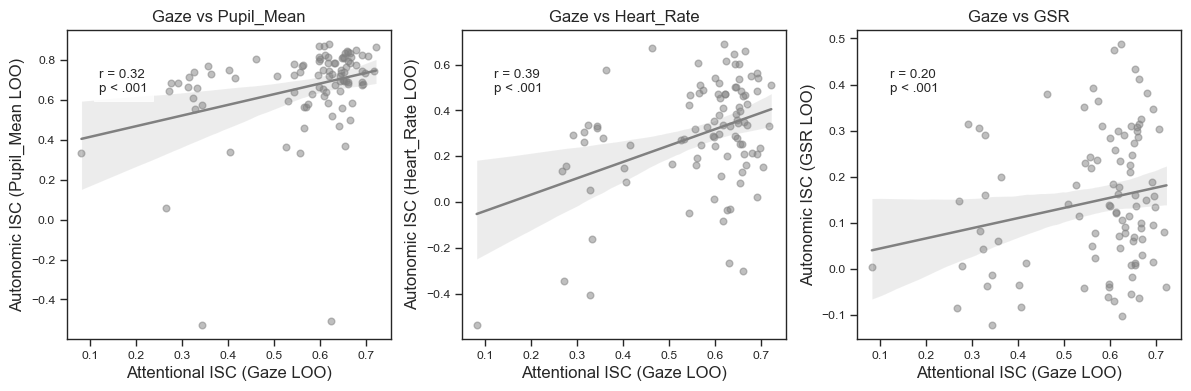

In [6]:
# 4. SCATTER PLOT VERIFICATION (Optional but great for the paper)
# This explicitly shows the correlation printed on the heatmaps
fig_scatter, ax_scatter = plt.subplots(1, 3, figsize=(12, 4))

for i, signal in enumerate(passenger_signals):
    if signal not in results:
        continue
        
    loo_physio = utils.process_analysis.compute_loo_score(results[signal])
    
    sns.regplot(x=gaze_sync_scores, y=loo_physio, ax=ax_scatter[i], color='gray', scatter_kws={'alpha':0.5})
    ax_scatter[i].set_xlabel("Attentional ISC (Gaze LOO)",fontsize = 12)
    ax_scatter[i].set_ylabel(f"Autonomic ISC ({signal} LOO)",fontsize = 12)
    ax_scatter[i].set_title(f"Gaze vs {signal}",fontsize = 12)
    
    # Add stats annotation
    r, p = pearsonr(gaze_sync_scores, loo_physio)
    ax_scatter[i].text(0.1, 0.8, f"r = {r:.2f}\np < .001", transform=ax_scatter[i].transAxes, 
                       bbox=dict(facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

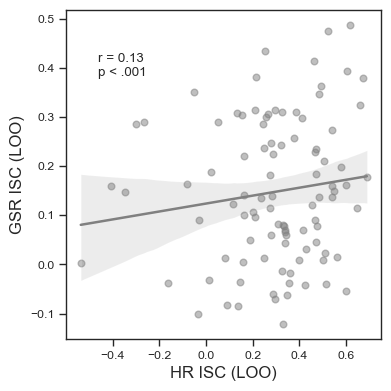

In [7]:
fig_scatter, ax_scatter = plt.subplots(1, 1, figsize=(4, 4))

loo_hr  = utils.process_analysis.compute_loo_score(results['Heart_Rate'])
loo_gsr = utils.process_analysis.compute_loo_score(results['GSR'])


sns.regplot(x=loo_hr, y=loo_gsr, ax=ax_scatter, color='gray', scatter_kws={'alpha':0.5})
ax_scatter.set_xlabel("HR ISC (LOO)",fontsize = 12)
ax_scatter.set_ylabel("GSR ISC (LOO)",fontsize = 12)
    
# Add stats annotation
r, p = pearsonr(loo_hr, loo_gsr)
ax_scatter.text(0.1, 0.8, f"r = {r:.2f}\np < .001", transform=ax_scatter.transAxes, 
                       bbox=dict(facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()